# PINN for transformer thermal modelling

Adapted from Bragone, Morozovska, Hilber, Laneryd & Luvisotto,
*Physics-informed neural networks for modelling power transformer's
dynamic thermal behaviour*, Electric Power Systems Research 211 (2022).

This notebook tests a physics-informed neural network using synthetic
ambient temperature, top-oil temperature and electrical load data.
Predictions are compared with a finite volume method (FVM) reference.

## Numerical model

The implementation uses the coefficients printed in the paper's
scaled Eq. 12:

$$
f := 1.8u_t - 0.05u_{xx}
- \left(15 + 83K(t)^2 - (u-T_a(t))\right)=0.
$$

Boundary conditions:

$$
u(0,t)=T_a(t), \qquad u(H,t)=T_o(t), \qquad H=1.
$$

The numerical time coordinate advances by one per hourly observation.
The coefficients are copied literally from Eq. 12; equivalence to
Table 1's SI coefficients expressed in hours has not been established.

## Network and training

- A temperature network takes height and time and predicts
  $\hat u(x,t)$.
- A time-only network predicts ambient temperature $\hat T_a(t)$
  and squared load $\widehat{K^2}(t)$.
- Predicted load loss is calculated as
  $\hat P_K(t)=\mu\widehat{K^2}(t)$.
- Both networks use tanh activations and are trained jointly using L-BFGS.

For controlled verification, the PINN is constrained toward the same
linear initial profile used by the FVM:

$$
u(x,0)=T_a(0)+[T_o(0)-T_a(0)]\frac{x}{H}.
$$

The total training loss is:

$$
\mathcal L =
\mathrm{MSE}_u +
\mathrm{MSE}_{P_K} +
\mathrm{MSE}_{T_a} +
\mathrm{MSE}_f +
\mathrm{MSE}_{IC}.
$$

The two-network architecture and initial-condition constraint are
adaptations of the paper's approach.

## Evaluation

Temperature predictions are evaluated against the FVM reference using
relative L2 error, with plots showing agreement and local differences.
The top-oil comparison includes boundary observations used in training,
so it measures reconstruction rather than prediction of future temperatures.

## Preliminary results

The saved single run reports:
- Temperature-field relative L2 error against FVM: approximately 2.09%.
- Top-oil relative L2 error: approximately 4.45%.
- Largest field difference on the evaluated grid: approximately 5.55 °C,
  at time coordinate 38 and height 0.99 m.

These results apply to this synthetic experiment. Repeatability across
three random seeds is still being evaluated.

For context, the paper's selected configuration reports relative L2
errors of 14.5% for the temperature field and 2.59% for top-oil temperature.
These are not directly comparable with this experiment because the data,
architecture and initial-condition constraints differ.

## Before running

Run the FVM reference notebook first to create `fvm_reference.npz`.
This file contains the synthetic input series and FVM reference solution.
Keep `heat_model.py` and `fvm_reference.npz` in the working directory
used by this notebook.

In [45]:
import os, time
import numpy as np
import torch
import torch.nn as nn
from scipy.stats import qmc
import matplotlib.pyplot as plt
from heat_model import PARAMS

# --------------------------------------------------------------------------
# SETUP: random seeds, compute device, and reference data.

# Load the input series and FVM reference solution from fvm_reference.npz.
# The current experiment uses synthetic inputs, not sensor measurements.
#
#   t_data                = numerical time coordinates (0, 1, ..., 99),
#                           one unit per hourly observation
#   Ta_data, To_data      = ambient and top-oil temperature input series
#   K_data                = electrical load-factor input series
#   x_fvm, U_fvm          = FVM cell centres and reference temperatures;
#                           U_fvm is used for evaluation, not training
#
# Both methods use the same sampled input series. Between observations,
# FVM interpolates the inputs, while the PINN approximates ambient
# temperature and squared load using a time-only network.
#
# Import the coefficients of the printed scaled Eq. 12 from heat_model.py.
# This experiment uses that equation as a numerical formulation; physical
# equivalence to Table 1's SI coefficients has not been established.
# --------------------------------------------------------------------------

torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# ref = np.load("fvm_reference.npz")
ref = np.load("fvm_reference_noise_free.npz")
x_fvm, t_data, U_fvm = ref["x"], ref["t"], ref["U"]          # U_fvm: (n_t, N_cells)
Ta_data, To_data, K_data = ref["Ta"], ref["To"], ref["K"]


if bool(ref["synthetic"]):
    print(
        "Using synthetic inputs: this experiment does not reproduce "
        "the paper's real-data results."
    )

H = PARAMS["H"]
a, k, h, P0, mu = (PARAMS[n] for n in ("a", "k", "h", "P0", "mu"))

lb = np.array([0.0, t_data.min()])     # domain lower bound [x_min, t_min]
ub = np.array([H, t_data.max()])       # domain upper bound [x_max, t_max]
print(
    f"device={device} | {len(t_data)} observation times | "
    f"coefficients: {PARAMS}" )

Using synthetic inputs: this experiment does not reproduce the paper's real-data results.
device=mps | 100 observation times | coefficients: {'a': 1.8, 'k': 0.05, 'h': 1.0, 'P0': 15.0, 'mu': 83.0, 'H': 1.0}


In [46]:
# --------------------------------------------------------------------------
# 1. TRAINING DATA: two sets of points.
#
# Pile 1 - Boundary targets:
#   x=0: temperature equals ambient temperature Ta(t).
#   x=H: temperature equals top-oil temperature To(t).
# Randomly select N_u points from these boundary observations.
# Each selected point carries targets for u, Ta and K^2.
# These targets come from synthetic input series in this experiment.
#
# Pile 2 - Physics-check points:
# Generate N_f points across height and time using Latin Hypercube sampling.
# Add the selected boundary points, giving N_f + N_u points in total.
# At these points, training checks the heat-equation residual;
# no reference temperature values are needed for that check.
#
# Initial-condition points are created separately inside train().
# --------------------------------------------------------------------------

def build_training_data(N_u, N_f, seed=1234):
    rng = np.random.default_rng(seed)
    n = len(t_data)
    X_bc = np.vstack([np.column_stack([np.zeros(n), t_data]),      # bottom
                      np.column_stack([np.full(n, H), t_data])])   # top
    u_bc  = np.concatenate([Ta_data, To_data])[:, None]
    Ta_bc = np.concatenate([Ta_data, Ta_data])[:, None]
    K2_bc = np.concatenate([K_data**2, K_data**2])[:, None]

    idx = rng.choice(len(X_bc), N_u, replace=False)
    X_f = lb + (ub - lb) * qmc.LatinHypercube(d=2, seed=seed).random(N_f)
    X_f = np.vstack([X_f, X_bc[idx]])          # Check the PDE at boundary samples too.
    return X_bc[idx], u_bc[idx], Ta_bc[idx], K2_bc[idx], X_f

In [47]:
# --------------------------------------------------------------------------
# 2. NETWORK: temperature and time-dependent inputs.
#
# Two networks predict three quantities:
#   temperature_net: (x, t) -> temperature u(x, t).
#   forcing_net:         t -> ambient temperature Ta(t) and squared load K(t)^2.
# Giving forcing_net only time prevents Ta and K^2 from varying with height.
# The heat-equation residual converts K^2 to load loss using P_K = mu*K^2.
#
# Both networks use the specified hidden-layer sizes, tanh activations,
# Xavier weight initialisation and zero biases.
#
# Inputs are scaled to [-1, 1]. Each output is multiplied by its training
# target's standard deviation and shifted by its mean to help optimisation.
# Losses are calculated using these rescaled outputs.
#
# --------------------------------------------------------------------------

# Build fully connected layers, with tanh between hidden layers:
def make_mlp(sizes):
    modules = []
    for i in range(len(sizes) - 1):
        layer = nn.Linear(sizes[i], sizes[i + 1])
        nn.init.xavier_normal_(layer.weight)
        nn.init.zeros_(layer.bias)
        modules.append(layer)
        if i < len(sizes) - 2:
            modules.append(nn.Tanh())
    return nn.Sequential(*modules)


class PINN(nn.Module):
    def __init__(self, layers, lb, ub, out_mean, out_std):
        super().__init__()

        self.register_buffer("lb", torch.tensor(lb, dtype=torch.float32))
        self.register_buffer("ub", torch.tensor(ub, dtype=torch.float32))
        self.register_buffer(
            "out_mean", torch.tensor(out_mean, dtype=torch.float32)
        )
        self.register_buffer(
            "out_std", torch.tensor(out_std, dtype=torch.float32)
        )

        hidden = layers[1:-1]

        self.temperature_net = make_mlp([2] + hidden + [1])
        self.forcing_net = make_mlp([1] + hidden + [2])

    def forward(self, x, t):
        x_scaled = 2 * (x - self.lb[0]) / (self.ub[0] - self.lb[0]) - 1
        t_scaled = 2 * (t - self.lb[1]) / (self.ub[1] - self.lb[1]) - 1

        u_raw = self.temperature_net(
            torch.cat([x_scaled, t_scaled], dim=1)
        )

        # These outputs cannot depend on height because x is never supplied.
        forcing_raw = self.forcing_net(t_scaled)

        u = u_raw * self.out_std[0] + self.out_mean[0]
        Ta_hat = forcing_raw[:, 0:1] * self.out_std[1] + self.out_mean[1]
        K2_hat = forcing_raw[:, 1:2] * self.out_std[2] + self.out_mean[2]

        return u, Ta_hat, K2_hat

def to_tensor(arr):
    return torch.tensor(arr, dtype=torch.float32, device=device)

In [48]:
# --------------------------------------------------------------------------
# 3. PHYSICS RESIDUAL: check agreement with the scaled heat equation (Eq. 12).
#     f = a*u_t - k*u_xx - (P0 + mu*K^2 - h*(u - Ta))
#
# Automatic differentiation computes the temperature derivatives:
#   u_t  = change in temperature over time.
#   u_xx = second derivative along the transformer's height.
#
# Ta_hat and K2_hat come from the time-only network, allowing the residual
# to be evaluated between observation times.
#
# A solution that satisfies the equation has f=0. During training,
# the mean squared residual penalises departures from the equation.
# --------------------------------------------------------------------------

def residual(model, x, t):
    x = x.clone().requires_grad_(True)
    t = t.clone().requires_grad_(True)
    u, Ta_hat, K2_hat = model(x, t)
    ones = torch.ones_like(u)
    u_t  = torch.autograd.grad(u, t, ones, create_graph=True)[0]
    u_x  = torch.autograd.grad(u, x, ones, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)[0]
    return a * u_t - k * u_xx - (P0 + mu * K2_hat - h * (u - Ta_hat))

In [49]:
# --------------------------------------------------------------------------
# 4. TRAIN: fit the network using L-BFGS (Limited-memory Broyden–Fletcher–Goldfarb–Shanno) optimisation.
#
# The total loss combines five mean squared errors:
#   loss_u  : temperature predictions versus boundary targets.
#   loss_PK : predicted load loss mu*K^2 versus supplied load-loss targets.
#   loss_Ta : predicted ambient temperature versus supplied targets.
#   loss_f  : heat-equation residual at physics-check points.
#   loss_ic : temperature at the starting time versus the linear profile
#             also used to initialise the FVM solver.
#
# The initial-condition loss is added for controlled verification;
# it extends the paper's boundary-only training setup.
#
# Each call creates and trains a fresh model. The seed controls initial
# weights and point sampling, allowing repeat runs and parameter sweeps.
# L-BFGS repeatedly calls closure() to calculate the loss and gradients.
# The returned counter records closure calls, not optimiser iterations.
# --------------------------------------------------------------------------

def train(N_u=100, N_f=10000, n_layers=4, n_neurons=50, max_iter=30000,
          seed=1234, print_every=1000):
    torch.manual_seed(seed)
    X_u, u_u, Ta_u, K2_u, X_f = build_training_data(N_u, N_f, seed)

    mean = np.array([u_u.mean(), Ta_u.mean(), K2_u.mean()])
    std  = np.array([u_u.std(),  Ta_u.std(),  K2_u.std()]) + 1e-8
    layers = [2] + [n_neurons] * n_layers + [3]
    model = PINN(layers, lb, ub, mean, std).to(device)

    xu, tu = to_tensor(X_u[:, 0:1]), to_tensor(X_u[:, 1:2])
    uu, Tau, K2u = to_tensor(u_u), to_tensor(Ta_u), to_tensor(K2_u)
    xf, tf = to_tensor(X_f[:, 0:1]), to_tensor(X_f[:, 1:2])

    # Sample the linear initial profile at 50 heights.
    x0 = to_tensor(np.linspace(0, H, 50)[:, None])
    t0_ic = torch.full_like(x0, float(t_data[0]))
    
    u0_target = (
        float(Ta_data[0])
        + (float(To_data[0]) - float(Ta_data[0])) * x0 / H
    )

    optimizer = torch.optim.LBFGS(
        model.parameters(), lr=1.0, max_iter=max_iter, max_eval=max_iter,
        history_size=50, tolerance_grad=1e-9, tolerance_change=1e-12,
        line_search_fn="strong_wolfe")

    it = [0]
    def closure():
        optimizer.zero_grad()
    
        # Evaluate boundary predictions and the heat-equation residual.
        u_p, Ta_p, K2_p = model(xu, tu)
        f = residual(model, xf, tf)
    
        loss_u = ((u_p - uu) ** 2).mean()
        loss_Ta = ((Ta_p - Tau) ** 2).mean()
        loss_PK = ((mu * K2_p - mu * K2u) ** 2).mean()
        loss_f = (f ** 2).mean()
    
        # Penalise differences from the FVM's assumed initial profile.
        u0_pred = model(x0, t0_ic)[0]
        loss_ic = ((u0_pred - u0_target) ** 2).mean()
    
        # Combine data, physics and initial-condition losses.
        loss = loss_u + loss_PK + loss_Ta + loss_f + loss_ic
    
        loss.backward()
        it[0] += 1
    
        if print_every and it[0] % print_every == 0:
            print(
                f"eval {it[0]:6d}  loss={loss.item():.3e}  "
                f"u={loss_u.item():.2e}  "
                f"PK={loss_PK.item():.2e}  "
                f"Ta={loss_Ta.item():.2e}  "
                f"f={loss_f.item():.2e}  "
                f"IC={loss_ic.item():.2e}"
            )
    
        return loss

    t0 = time.time()
    optimizer.step(closure)
    return model, X_u, it[0], time.time() - t0

In [50]:
# --------------------------------------------------------------------------
# 5. EVALUATE: compare PINN predictions with reference temperatures.
#
# Predict the temperature field on the FVM grid and the top-oil
# temperature at x=H for every observation time.
#
#   err_u  : relative L2 error against the FVM temperature field.
#   err_To : relative L2 error against the supplied top-oil series
#            (synthetic in this experiment).
#
# Relative L2 error = norm(prediction - reference) / norm(reference).
# Smaller values indicate closer agreement.
#
# The top-oil comparison includes boundary points used during training;
# it measures reconstruction accuracy, not independent forecasting.
# Evaluation runs without calculating gradients.
# --------------------------------------------------------------------------

def evaluate(model):
    model.eval()
    Xg, Tg = np.meshgrid(x_fvm, t_data)                       # (n_t, N_cells)
    with torch.no_grad():
        u_pred = model(to_tensor(Xg.reshape(-1, 1)),
                       to_tensor(Tg.reshape(-1, 1)))[0].cpu().numpy().reshape(Xg.shape)
        To_pred = model(to_tensor(np.full((len(t_data), 1), H)),
                        to_tensor(t_data[:, None]))[0].cpu().numpy().ravel()
    err_u  = np.linalg.norm(U_fvm - u_pred) / np.linalg.norm(U_fvm)
    err_To = np.linalg.norm(To_data - To_pred) / np.linalg.norm(To_data)
    return err_u, err_To, u_pred, To_pred

## 6. Single run with the paper's best configuration

On a laptop CPU this takes minutes to tens of minutes. The paper reports about 2 hours for its
best run. Lower `MAX_ITER` for a quick test.

In [51]:
MAX_ITER = 30000

model, X_u_train, n_iter, secs = train(N_u=100, N_f=10000, n_layers=4, n_neurons=50,
                                       max_iter=MAX_ITER)
err_u, err_To, u_pred, To_pred = evaluate(model)

print(f"\n{n_iter} loss evaluations, {secs/60:.1f} min")
print(f"Relative L2 error, u vs FVM : {err_u:.3e}   (paper: 1.45e-01)")
print(f"Relative L2 error, To       : {err_To:.3e}   (paper: 2.59e-02)")

torch.save(
    model.state_dict(),
    "pinn_noise_free_Nu100_seed1234.pt"
)

eval   1000  loss=1.778e+01  u=2.06e+00  PK=7.80e+00  Ta=4.54e+00  f=3.16e+00  IC=2.27e-01
eval   2000  loss=5.168e-01  u=7.64e-02  PK=2.26e-02  Ta=5.96e-02  f=2.73e-01  IC=8.56e-02
eval   3000  loss=1.825e-01  u=3.44e-02  PK=7.43e-03  Ta=9.65e-03  f=9.26e-02  IC=3.84e-02
eval   4000  loss=8.167e-02  u=1.24e-02  PK=5.86e-03  Ta=6.40e-03  f=4.67e-02  IC=1.03e-02
eval   5000  loss=4.109e-02  u=6.49e-03  PK=2.21e-03  Ta=4.29e-03  f=2.40e-02  IC=4.12e-03
eval   6000  loss=2.658e-02  u=3.97e-03  PK=1.59e-03  Ta=3.03e-03  f=1.63e-02  IC=1.74e-03

6913 loss evaluations, 5.0 min
Relative L2 error, u vs FVM : 4.924e-03   (paper: 1.45e-01)
Relative L2 error, To       : 1.067e-02   (paper: 2.59e-02)


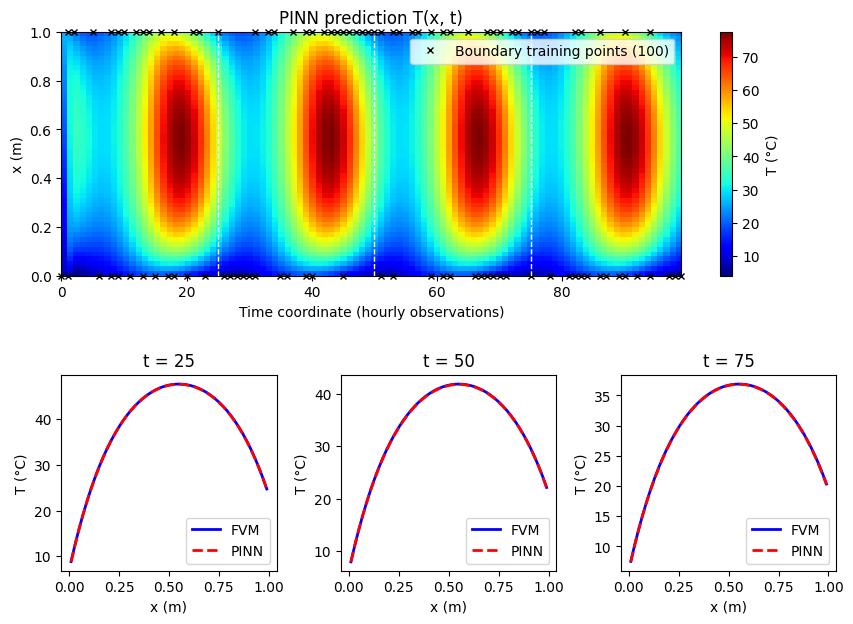

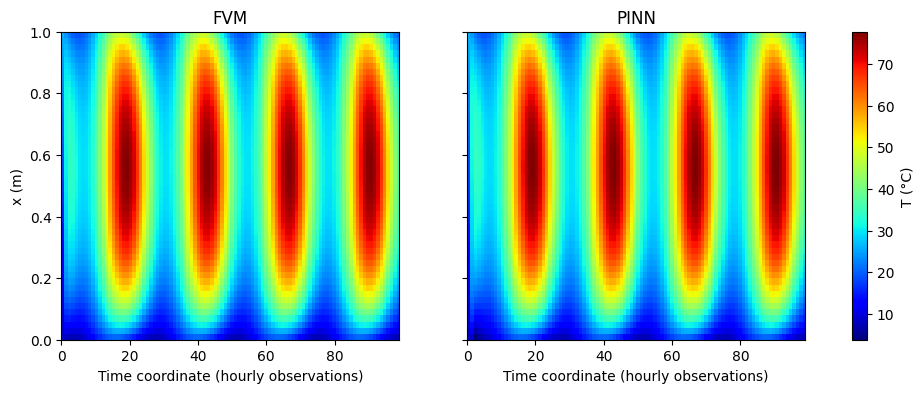

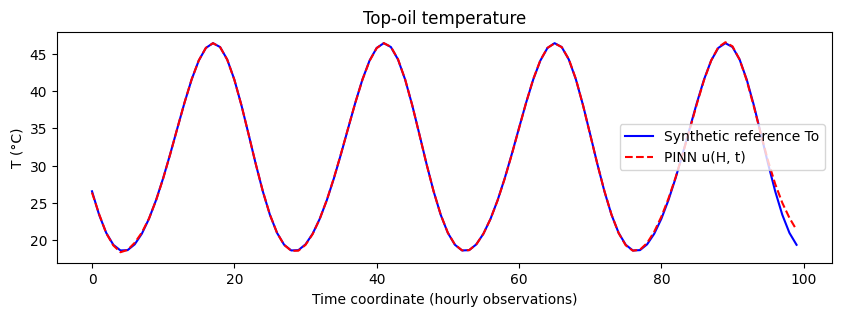

In [53]:
# --------------------------------------------------------------------------
# PLOTS: visual comparison of PINN and FVM temperatures.
#
# Inspired by the paper's Figs. 4 and 5, using this experiment's synthetic data:
#   1. PINN temperature heatmap and profiles at times 25, 50 and 75.
#      Black crosses mark sampled boundary training points.
#   2. FVM and PINN heatmaps with the same colour scale for comparison.
#   3. Predicted top-oil temperature versus the synthetic reference series.
#
# Saves each figure as a PNG.
# --------------------------------------------------------------------------

vmin, vmax = min(U_fvm.min(), u_pred.min()), max(U_fvm.max(), u_pred.max())
ext = [t_data.min(), t_data.max(), 0, H]

# PINN heatmap and temperature profiles at three selected times:
fig = plt.figure(figsize=(10, 7))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.8], hspace=0.45, wspace=0.3)
ax0 = fig.add_subplot(gs[0, :])
im = ax0.imshow(u_pred.T, origin="lower", aspect="auto", cmap="jet",
                extent=ext, vmin=vmin, vmax=vmax)
fig.colorbar(im, ax=ax0, label="T (°C)")
ax0.plot(X_u_train[:, 1], X_u_train[:, 0], "kx", ms=4, clip_on=False,
         label=f"Boundary training points ({len(X_u_train)})")
for tv in [25, 50, 75]:
    ax0.axvline(tv, color="w", ls="--", lw=1)
ax0.set_xlabel("Time coordinate (hourly observations)"); ax0.set_ylabel("x (m)"); ax0.set_title("PINN prediction T(x, t)")
ax0.legend(loc="upper right")
for i, tv in enumerate([25, 50, 75]):
    ax = fig.add_subplot(gs[1, i])
    ax.plot(x_fvm, U_fvm[tv], "b-", lw=2, label="FVM")
    ax.plot(x_fvm, u_pred[tv], "r--", lw=2, label="PINN")
    ax.set_title(f"t = {t_data[tv]:g}")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("T (°C)")
    ax.legend()
plt.savefig("pinn_noise_free_Nu100_seed1234_fig4.png", dpi=150, bbox_inches="tight")
plt.show()

# Compare the full temperature fields using a shared colour scale.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, data, title in zip(axes, [U_fvm, u_pred], ["FVM", "PINN"]):
    im = ax.imshow(data.T, origin="lower", aspect="auto", cmap="jet",
                   extent=ext, vmin=vmin, vmax=vmax)
    ax.set_title(title); ax.set_xlabel("Time coordinate (hourly observations)")
axes[0].set_ylabel("x (m)")
fig.colorbar(im, ax=axes, label="T (°C)")
plt.savefig("pinn_noise_free_Nu100_seed1234_fig5.png", dpi=150, bbox_inches="tight")
plt.show()

# Compare top-oil predictions with the synthetic reference: 
plt.figure(figsize=(10, 3))
plt.plot(t_data, To_data, "b-", label="Synthetic reference To")
plt.plot(t_data, To_pred, "r--", label="PINN u(H, t)")
plt.xlabel("Time coordinate (hourly observations)"); plt.ylabel("T (°C)"); plt.title("Top-oil temperature"); plt.legend()
plt.savefig("pinn_noise_free_Nu100_seed1234_top_oil.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Hyperparameter sweep (paper Tables 3–6)

- **Tables 3 & 4:** 4 × 50 network, varying $N_u \in \{50,100,150\}$ and $N_f \in \{2000,5000,10000\}$ (9 runs)
- **Tables 5 & 6:** $N_u=100$, $N_f=10{,}000$, varying layers $\in\{2,4,6\}$ × neurons $\in\{10,20,50,100\}$ (12 runs)

That's 20 distinct runs, because one configuration appears in both groups. This can take **many hours**, so it is off by
default. Results are appended to `sweep_results_time_only_ic.csv` after every run, and finished runs are
skipped on a re-run, so it is safe to interrupt and resume. Note that the paper reports a single
run per configuration; differences between neighbouring cells may be within seed-to-seed noise.

In [79]:
# --------------------------------------------------------------------------
# 7. HYPERPARAMETER SWEEP: compare 20 network and sampling configurations.
#
# Save errors and training times after each run. Existing configurations
# are skipped so an interrupted sweep can resume.
# RUN_SWEEP=False skips training but displays saved tables if available.
# --------------------------------------------------------------------------

import pandas as pd

RUN_SWEEP = False
SWEEP_MAX_ITER = 30000
RESULTS = "sweep_results_noise_free_time_only_ic.csv"

# Vary point counts for a fixed network, then vary network depth and width:
configs = [(Nu, Nf, 4, 50) for Nu in [50, 100, 150] for Nf in [2000, 5000, 10000]]
configs += [(100, 10000, L, n) for L in [2, 4, 6] for n in [10, 20, 50, 100]
            if (L, n) != (4, 50)]                      # 4x50 already in the first group

# Train and evaluate configurations not already recorded in the CSV.
if RUN_SWEEP:
    
    # Load previous results so completed configurations can be skipped.
    done = pd.read_csv(RESULTS) if os.path.exists(RESULTS) else pd.DataFrame()
    for Nu, Nf, L, n in configs:
        if len(done) and ((done.N_u == Nu) & (done.N_f == Nf) &
                          (done.layers == L) & (done.neurons == n)).any():
            continue
        print(f"--- N_u={Nu} N_f={Nf} layers={L} neurons={n}")

        m, _, evaluations, secs = train(
            Nu, Nf, L, n, max_iter=SWEEP_MAX_ITER, print_every=0
        )

        # Calculate errors for the model just trained.
        e_u, e_To, _, _ = evaluate(m)

        row = dict(
            N_u=Nu, N_f=Nf, layers=L, neurons=n,
            err_u=e_u, err_To=e_To,
            evaluations=evaluations, minutes=secs / 60
        )

        print(row)
        done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)

        # Save progress after each completed run.
        done.to_csv(RESULTS, index=False)

# Arrange saved errors into tables, following the paper's parameter groupings:
if os.path.exists(RESULTS):
    res = pd.read_csv(RESULTS)
    g1 = res[(res.layers == 4) & (res.neurons == 50)]
    g2 = res[(res.N_u == 100) & (res.N_f == 10000)]
    fmt = "{:.2e}".format
    print("Table 3 - err_u (rows N_u, cols N_f)");  print(g1.pivot(index="N_u", columns="N_f", values="err_u").to_string(float_format=fmt))
    print("\nTable 4 - err_To");                     print(g1.pivot(index="N_u", columns="N_f", values="err_To").to_string(float_format=fmt))
    print("\nTable 5 - err_u (rows layers, cols neurons)"); print(g2.pivot(index="layers", columns="neurons", values="err_u").to_string(float_format=fmt))
    print("\nTable 6 - err_To");                     print(g2.pivot(index="layers", columns="neurons", values="err_To").to_string(float_format=fmt))